## Feature Extraction using OpenSMILE and Classification using SVM And Gradient Boosting

In [ ]:
!pip install opensmile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 6.1 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd

import librosa
import opensmile

from scipy.stats import kurtosis, skew

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
TRAIN_CSV = "/content/train_data.csv"
TEST_CSV = "/content/test_data.csv"

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Train shape: (830, 5)
Test shape: (121, 5)


,File Name,New File Path,Duration,Binary Label,Multi-class Label
0,H_TE_002_G_F_024_001.mp3_time_shift.mp3,/content/augmented_audios/H_TE_002_G_F_024_001...,11.032063,1,1
1,H_TE_002_G_M_019_001.mp3,/content/resampled_audios/Hate/Gender/H_TE_002...,7.720975,1,1
2,H_TE_002_G_M_009_002.mp3,/content/resampled_audios/Hate/Gender/H_TE_002...,6.768957,1,1
3,H_TE_002_G_F_035_002.mp3_add_noise.mp3,/content/augmented_audios/H_TE_002_G_F_035_002...,3.718437,1,1
4,NH_TE_001_N_M_040_002.mp3,/content/resampled_audios/Non Hate/NH_TE_001_N...,14.444444,0,4


In [ ]:
print(train_df.columns.tolist())

['File Name', 'New File Path', 'Duration', 'Binary Label', 'Multi-class Label']


## Create the OpenSMILE extractor

In [ ]:
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.ComParE_2016,
    feature_level=opensmile.FeatureLevel.LowLevelDescriptors
)

This selects:
- ZCR
- RMS Energy
- Voicing
- MFCC 1–12

In [ ]:
OPENSMILE_FEATURES = (
    [
        "pcm_zcr_sma",
        "pcm_RMSenergy_sma",
        "voicingFinalUnclipped_sma"
    ]
    + [f"mfcc_sma[{i}]" for i in range(1, 13)]
)

print("Number of selected features:", len(OPENSMILE_FEATURES))
print(OPENSMILE_FEATURES)

Number of selected features: 15
['pcm_zcr_sma', 'pcm_RMSenergy_sma', 'voicingFinalUnclipped_sma', 'mfcc_sma[1]', 'mfcc_sma[2]', 'mfcc_sma[3]', 'mfcc_sma[4]', 'mfcc_sma[5]', 'mfcc_sma[6]', 'mfcc_sma[7]', 'mfcc_sma[8]', 'mfcc_sma[9]', 'mfcc_sma[10]', 'mfcc_sma[11]', 'mfcc_sma[12]']


## Extract frame-level OpenSMILE features

In [ ]:
def extract_opensmile_features(audio_path):
    """
    Extract the selected OpenSMILE low-level descriptors
    from one audio file.
    """

    signal, sr = librosa.load(audio_path, sr=None)

    features = smile.process_signal(signal, sr)

    features = features[OPENSMILE_FEATURES]

    return features

At this stage, one audio file has many rows, because OpenSMILE produces features over time.

## Convert frame-level features into one vector

For every selected feature, it calculates:

- Maximum
- Maximum position
- Range
- Median
- Kurtosis
- Skewness
- Standard deviation
- Linear regression coefficient 0
- Linear regression coefficient 1
- Quadratic error

In [ ]:
def calculate_statistical_features(features_df):

    stats = {}

    for column in features_df.columns:

        data = features_df[column].dropna().values

        if len(data) == 0:
            continue

        # 1. Maximum
        stats[f"{column}_max"] = np.max(data)

        # 2. Position of maximum
        max_pos = np.argmax(data) / len(data)
        stats[f"{column}_max_pos"] = max_pos

        # 3. Range
        stats[f"{column}_range"] = np.max(data) - np.min(data)

        # 4. Median
        stats[f"{column}_median"] = np.median(data)

        # 5. Kurtosis
        stats[f"{column}_kurtosis"] = kurtosis(data)

        # 6. Skewness
        stats[f"{column}_skewness"] = skew(data)

        # 7. Standard deviation
        stats[f"{column}_std_dev"] = np.std(data)

        # Linear regression
        x = np.arange(len(data))

        linear_coefficients = np.polyfit(x, data, 1)

        # 8. Linear regression coefficient 0
        stats[f"{column}_lin_reg_coef_0"] = linear_coefficients[0]

        # 9. Linear regression coefficient 1
        stats[f"{column}_lin_reg_coef_1"] = linear_coefficients[1]

        # 10. Quadratic error
        predicted = np.polyval(linear_coefficients, x)

        quadratic_error = np.sum(
            (predicted - data) ** 2
        )

        stats[f"{column}_quad_error"] = quadratic_error

    return pd.Series(stats)

## Create one 150-feature vector per audio file

In [ ]:
def extract_audio_feature_vector(audio_path):

    # Extract frame-level OpenSMILE features
    frame_features = extract_opensmile_features(audio_path)

    # Convert frame-level features into fixed-length vector
    feature_vector = calculate_statistical_features(
        frame_features
    )

    # Handle infinity and missing values
    feature_vector = feature_vector.replace(
        [np.inf, -np.inf],
        np.nan
    )

    feature_vector = feature_vector.fillna(0)

    return feature_vector.values.astype(np.float32)

In [ ]:
# Check the available columns
print(train_df.columns.tolist())

['File Name', 'New File Path', 'Duration', 'Binary Label', 'Multi-class Label']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!cp -r /content/drive/MyDrive/telugu_dataset /content/

In [ ]:
import os

DATASET_DIR = "/content/telugu_dataset"

audio_file_map = {}

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith((".mp3", ".wav", ".m4a", ".flac")):
            audio_file_map[file] = os.path.join(root, file)

print("Total audio files found:", len(audio_file_map))

# Show a few examples
for filename, path in list(audio_file_map.items())[:10]:
    print(filename, "->", path)

Total audio files found: 601
H_TE_002_G_F_041_001.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_F_041_001.mp3
H_TE_002_G_M_034_002.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_034_002.mp3
H_TE_002_G_M_010_005.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_010_005.mp3
H_TE_002_G_F_033_002.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_F_033_002.mp3
H_TE_002_G_M_013_002.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_013_002.mp3
H_TE_002_G_M_028_001.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_028_001.mp3
H_TE_002_G_M_010_001.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_010_001.mp3
H_TE_002_G_M_013_003.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_013_003.mp3
H_TE_002_G_M_004_003.mp3 -> /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_004_003.mp3
H_TE_002

In [ ]:
train_original = train_df[
    train_df["File Name"].isin(audio_file_map.keys())
].copy()

test_original = test_df[
    test_df["File Name"].isin(audio_file_map.keys())
].copy()

print("Original training samples:", len(train_original))
print("Original testing samples :", len(test_original))

Original training samples: 480
Original testing samples : 121


## Create the correct audio paths

In [ ]:
train_original["Audio Path"] = train_original["File Name"].map(
    audio_file_map
)

test_original["Audio Path"] = test_original["File Name"].map(
    audio_file_map
)

In [ ]:
print(train_original.iloc[0]["Audio Path"])
print(os.path.exists(train_original.iloc[0]["Audio Path"]))

/content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_019_001.mp3
True


## Check one audio file

In [ ]:
sample_audio = train_original.iloc[0]["Audio Path"]

print("Audio:", sample_audio)

sample_features = extract_audio_feature_vector(sample_audio)

print("Feature vector shape:", sample_features.shape)

Audio: /content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender/H_TE_002_G_M_019_001.mp3
Feature vector shape: (150,)


## Extract OpenSMILE features from all training/testing audio

In [ ]:
def create_feature_matrix(df):
    all_features = []
    valid_indices = []

    for i, row in df.iterrows():
        audio_path = row["Audio Path"]
        try:
            features = extract_audio_feature_vector(audio_path)
            all_features.append(features)
            valid_indices.append(i)

        except Exception as e:
            print(f"\nError processing: {audio_path}")
            print(e)

    X = np.array(all_features, dtype=np.float32)
    valid_df = df.loc[valid_indices].reset_index(drop=True)

    return X, valid_df

In [ ]:
X_train, train_valid = create_feature_matrix(train_original)

X_test, test_valid = create_feature_matrix(test_original)

## Check the extracted data

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("Train samples:", len(train_valid))
print("Test samples :", len(test_valid))

X_train shape: (480, 150)
X_test shape : (121, 150)
Train samples: 480
Test samples : 121


## Get the labels

## Binary

In [ ]:
y_train_binary = train_valid["Binary Label"].values
y_test_binary = test_valid["Binary Label"].values

## Multiclass

In [ ]:
y_train_multi = train_valid["Multi-class Label"].values
y_test_multi = test_valid["Multi-class Label"].values

In [ ]:
print("Binary labels:")
print(np.unique(y_train_binary, return_counts=True))

print("\nMulticlass labels:")
print(np.unique(y_train_multi, return_counts=True))

Binary labels:
(array([0, 1]), array([166, 314]))

Multiclass labels:
(array([0, 1, 2, 3, 4]), array([104,  86,  56,  68, 166]))


## Train OpenSMILE + SVM - Binary

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_binary = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_binary.fit(X_train, y_train_binary)
svm_binary_pred = svm_binary.predict(X_test)

## SVM Binary - Accuracy, F1, Classification Report

In [ ]:
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix

svm_binary_accuracy = accuracy_score(y_test_binary,svm_binary_pred)
svm_binary_f1 = f1_score(y_test_binary,svm_binary_pred)

print("===== OpenSMILE + SVM : Binary =====")
print(f"Accuracy : {svm_binary_accuracy * 100:.2f}%")
print(f"F1 Score : {svm_binary_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_binary,svm_binary_pred))

===== OpenSMILE + SVM : Binary =====
Accuracy : 81.82%
F1 Score : 0.8690

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.62      0.70        42
           1       0.82      0.92      0.87        79

    accuracy                           0.82       121
   macro avg       0.82      0.77      0.79       121
weighted avg       0.82      0.82      0.81       121



## SVM - Binary Confusion Matrix

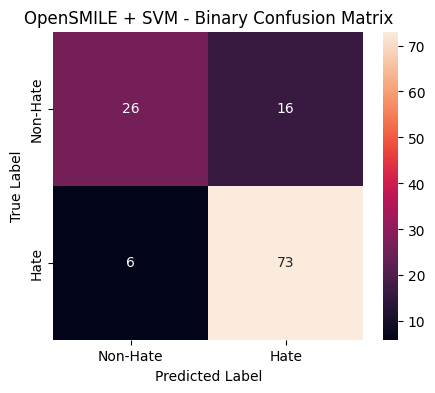

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_binary,svm_binary_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(cm,annot=True,fmt="d",xticklabels=["Non-Hate", "Hate"],yticklabels=["Non-Hate", "Hate"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("OpenSMILE + SVM - Binary Confusion Matrix")
plt.show()

## Train OpenSMILE + SVM - Multiclass

In [ ]:
svm_multi = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svm_multi.fit(X_train, y_train_multi)

svm_multi_pred = svm_multi.predict(X_test)

## SVM Multiclass - Accuracy, F1, Classification Report

In [ ]:
svm_multi_accuracy = accuracy_score(y_test_multi,svm_multi_pred)
svm_multi_f1 = f1_score(y_test_multi,svm_multi_pred,average="macro")

print("===== OpenSMILE + SVM : Multiclass =====")
print(f"Accuracy : {svm_multi_accuracy * 100:.2f}%")
print(f"Macro F1 : {svm_multi_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_multi,svm_multi_pred))

===== OpenSMILE + SVM : Multiclass =====
Accuracy : 63.64%
Macro F1 : 0.5859

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.71      0.69        28
           1       0.88      0.56      0.68        25
           2       0.88      0.58      0.70        12
           3       0.29      0.14      0.19        14
           4       0.57      0.81      0.67        42

    accuracy                           0.64       121
   macro avg       0.65      0.56      0.59       121
weighted avg       0.65      0.64      0.62       121



## SVM Multiclass Confusion Matrix

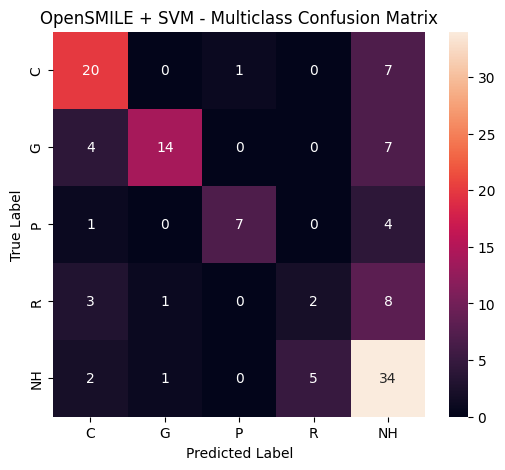

In [ ]:
cm = confusion_matrix(y_test_multi,svm_multi_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(cm,annot=True,fmt="d",xticklabels=["C", "G", "P", "R", "NH"],yticklabels=["C", "G", "P", "R", "NH"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("OpenSMILE + SVM - Multiclass Confusion Matrix")
plt.show()

## Gradient Boosting - Binary

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_binary = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_binary.fit(X_train,y_train_binary)
gb_binary_pred = gb_binary.predict(X_test)

## Gradient Boosting Binary - Accuracy, F1, Report

In [ ]:
gb_binary_accuracy = accuracy_score(y_test_binary,gb_binary_pred)
gb_binary_f1 = f1_score(y_test_binary,gb_binary_pred)

print("===== OpenSMILE + Gradient Boosting : Binary =====")
print(f"Accuracy : {gb_binary_accuracy * 100:.2f}%")
print(f"F1 Score : {gb_binary_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_binary,gb_binary_pred))

===== OpenSMILE + Gradient Boosting : Binary =====
Accuracy : 81.82%
F1 Score : 0.8659

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.67      0.72        42
           1       0.84      0.90      0.87        79

    accuracy                           0.82       121
   macro avg       0.81      0.78      0.79       121
weighted avg       0.82      0.82      0.81       121



## Gradient Boosting - Multiclass

In [ ]:
gb_multi = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_multi.fit(X_train,y_train_multi)
gb_multi_pred = gb_multi.predict(X_test)

## Gradient Boosting Multiclass - Accuracy, F1, Report

In [ ]:
gb_multi_accuracy = accuracy_score(y_test_multi,gb_multi_pred)
gb_multi_f1 = f1_score(y_test_multi,gb_multi_pred,average="macro")

print("===== OpenSMILE + Gradient Boosting : Multiclass =====")
print(f"Accuracy : {gb_multi_accuracy * 100:.2f}%")
print(f"Macro F1 : {gb_multi_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_multi,gb_multi_pred))

===== OpenSMILE + Gradient Boosting : Multiclass =====
Accuracy : 59.50%
Macro F1 : 0.5234

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.71      0.69        28
           1       0.79      0.44      0.56        25
           2       0.71      0.42      0.53        12
           3       0.14      0.14      0.14        14
           4       0.61      0.81      0.69        42

    accuracy                           0.60       121
   macro avg       0.58      0.50      0.52       121
weighted avg       0.61      0.60      0.59       121



## Final comparison table

In [ ]:
results = pd.DataFrame({
    "Model": [
        "OpenSMILE + SVM",
        "OpenSMILE + SVM",
        "OpenSMILE + Gradient Boosting",
        "OpenSMILE + Gradient Boosting"
    ],

    "Task": [
        "Binary",
        "Multiclass",
        "Binary",
        "Multiclass"
    ],

    "Accuracy (%)": [
        svm_binary_accuracy * 100,
        svm_multi_accuracy * 100,
        gb_binary_accuracy * 100,
        gb_multi_accuracy * 100
    ],

    "F1 Score": [
        svm_binary_f1,
        svm_multi_f1,
        gb_binary_f1,
        gb_multi_f1
    ]
})

results

,Model,Task,Accuracy (%),F1 Score
0,OpenSMILE + SVM,Binary,81.818182,0.869048
1,OpenSMILE + SVM,Multiclass,63.636364,0.585945
2,OpenSMILE + Gradient Boosting,Binary,81.818182,0.865854
3,OpenSMILE + Gradient Boosting,Multiclass,59.504132,0.523362
